# Educational Support Dashboard bằng code (pandas + pyplot)

Làm lại đúng bố cục dashboard trong Power BI: 1 header, 4 thẻ KPI, 4 biểu đồ.
Bảng đối chiếu với Power BI:

| Power BI | Code Python |
|---|---|
| Power Query (Append, đổi kiểu) | `pd.read_csv` + `pd.concat` |
| Calculated column | `np.select`, `np.where` |
| Measure / Card | tính bằng pandas, in bằng `ax.text` |
| Biểu đồ | `df.plot.bar` / `df.plot.barh` / `plt.barh` |
| Slicer | truyền dữ liệu đã lọc vào hàm `ve_dashboard()` |

## Bước 1. Đọc dữ liệu và gộp 2 file

In [ ]:
import pandas as pd, numpy as np
import matplotlib.pyplot as plt

mat = pd.read_csv("student-mat.csv", sep=";"); mat["Subject"] = "Math"
por = pd.read_csv("student-por.csv", sep=";"); por["Subject"] = "Portuguese"
df = pd.concat([mat, por], ignore_index=True)
print(df.shape)

(1044, 34)


## Bước 2. Tạo 2 cột mới (giống calculated column)

- `Muc_Nguy_Co`: chấm điểm rủi ro, mỗi dấu hiệu xấu +1 điểm (từng trượt môn, G1 dưới 10, vắng từ 10 buổi). Từ 2 điểm là **Cao**, 1 điểm là **Trung bình**, 0 điểm là **Thấp**.
- `Co_Ho_Tro`: **Có** nếu nhận ít nhất một trong 3 hình thức (`schoolsup`, `famsup`, `paid`).

In [2]:
diem = (df.failures >= 1).astype(int) + (df.G1 < 10).astype(int) + (df.absences >= 10).astype(int)
df["Muc_Nguy_Co"] = np.select([diem >= 2, diem == 1], ["Cao", "Trung bình"], default="Thấp")
df["Co_Ho_Tro"] = np.where((df.schoolsup == "yes") | (df.famsup == "yes") | (df.paid == "yes"), "Có", "Không")

print(df.Muc_Nguy_Co.value_counts().to_dict())     # đối chiếu: Thấp 607, Trung bình 267, Cao 170
print((df.Co_Ho_Tro == "Có").sum())                 # đối chiếu: 717

{'Thấp': 607, 'Trung bình': 267, 'Cao': 170}
717


## Bước 3. Viết hàm vẽ dashboard

Ý tưởng chính:
1. `fig.add_gridspec(4, 4)` chia trang thành lưới 4 hàng × 4 cột. Header chiếm cả hàng 0, 4 thẻ KPI ở hàng 1, 4 biểu đồ chiếm 2 cột × 2 hàng còn lại.
2. **Thẻ KPI** thực chất là một `Axes` trống nền trắng, bên trong dùng `ax.text` ghi tên và con số.
3. **3 biểu đồ cột** dùng `df.plot.bar` / `df.plot.barh`, truyền `ax=` để vẽ đúng ô.
4. **Thanh tiến độ** (thay cho gauge) vẽ bằng `barh`: một thanh xám dài 100% làm nền, một thanh xanh chồng lên là giá trị, và một vạch đứng đánh dấu mục tiêu.

In [3]:
BLUE, NAVY, GREY = "#118DFF", "#12239E", "#c8c6c4"
THU_TU = ["Thấp", "Trung bình", "Cao"]          # thứ tự trục x (không để A-Z)

def o_trang(ax):
    # biến Axes thành một "thẻ" nền trắng, không trục
    ax.set_facecolor("white")
    ax.set_xticks([]); ax.set_yticks([])
    for s in ax.spines.values(): s.set_visible(False)

def chart_style(ax, title):
    ax.set_title(title, loc="left", fontsize=11, fontweight="bold")
    ax.set_xlabel("")
    ax.spines[["top", "right"]].set_visible(False)

def ve_dashboard(d, muc_tieu=0.8):
    cao = d[d.Muc_Nguy_Co == "Cao"]
    n_cao = len(cao)
    bao_phu = (cao.Co_Ho_Tro == "Có").mean() if n_cao else 0
    ty_le_dat = (d.G3 >= 10).mean()
    ho_tro_bk = (d.Co_Ho_Tro == "Có").sum()

    fig = plt.figure(figsize=(14, 9), facecolor="#e9e9e9")
    gs = fig.add_gridspec(4, 4, height_ratios=[1.1, 0.8, 3, 3], hspace=0.35, wspace=0.2)

    # --- header
    ax = fig.add_subplot(gs[0, :]); o_trang(ax); ax.set_facecolor("#0d1b7a")
    ax.text(0.01, 0.5, "Educational Support Dashboard", color="white", fontsize=26,
            fontweight="bold", va="center", transform=ax.transAxes)

    # --- 4 thẻ KPI
    kpis = [("Bao phủ hỗ trợ", f"{bao_phu:.2%}"), ("Nhóm nguy cơ", f"{n_cao}"),
            ("Tỷ lệ đạt", f"{ty_le_dat:.2%}"), ("Hỗ trợ bất kỳ", f"{ho_tro_bk}")]
    for i, (ten, gt) in enumerate(kpis):
        ax = fig.add_subplot(gs[1, i]); o_trang(ax)
        ax.text(0.05, 0.68, ten, fontsize=10, color="#555", transform=ax.transAxes)
        ax.text(0.05, 0.14, gt, fontsize=20, transform=ax.transAxes)

    # --- 1) cột nhóm: số lượt theo mức nguy cơ x có hỗ trợ
    ax = fig.add_subplot(gs[2, :2])
    c1 = pd.crosstab(d.Muc_Nguy_Co, d.Co_Ho_Tro).reindex(THU_TU).reindex(columns=["Có", "Không"], fill_value=0)
    c1.plot.bar(ax=ax, color=[BLUE, NAVY], rot=0, width=0.75)
    for c in ax.containers: ax.bar_label(c, fontsize=8)
    ax.legend(title="Có hỗ trợ", frameon=False, fontsize=8)
    chart_style(ax, "Số lượt học theo mức nguy cơ và hỗ trợ")

    # --- 2) cột ngang: số lượt theo hình thức hỗ trợ
    ax = fig.add_subplot(gs[2, 2:])
    hinh_thuc = (d[["schoolsup", "famsup", "paid"]] == "yes").sum()
    hinh_thuc.index = ["Nhà trường", "Gia đình", "Học thêm trả phí"]
    hinh_thuc.sort_values().plot.barh(ax=ax, color=BLUE)
    ax.bar_label(ax.containers[0], fontsize=8)
    ax.margins(x=0.1)                                   # chừa chỗ cho nhãn số
    chart_style(ax, "Phân bổ hình thức hỗ trợ")

    # --- 3) cột nhóm: điểm G3 trung bình
    ax = fig.add_subplot(gs[3, :2])
    c3 = d.groupby(["Muc_Nguy_Co", "Co_Ho_Tro"]).G3.mean().unstack().reindex(THU_TU).reindex(columns=["Có", "Không"])
    c3.plot.bar(ax=ax, color=[BLUE, NAVY], rot=0, width=0.75)
    for c in ax.containers: ax.bar_label(c, fmt="%.1f", fontsize=8)
    ax.legend(title="Có hỗ trợ", frameon=False, fontsize=8)
    chart_style(ax, "Điểm G3 trung bình theo mức nguy cơ và hỗ trợ")

    # --- 4) thanh tiến độ: bao phủ hỗ trợ so với mục tiêu
    ax = fig.add_subplot(gs[3, 2:]); o_trang(ax)
    ax.barh(0, 1, color=GREY, height=0.4)                          # thanh nền = 100%
    ax.barh(0, bao_phu, color=BLUE, height=0.4)                    # thanh xanh = giá trị
    ax.plot([muc_tieu, muc_tieu], [-0.35, 0.35], color=NAVY, lw=2) # vạch mục tiêu
    ax.text(muc_tieu, 0.45, f"Mục tiêu {muc_tieu:.0%}", ha="center", fontsize=9)
    ax.text(0, -0.45, "0%", ha="left", fontsize=8)
    ax.text(1, -0.45, "100%", ha="right", fontsize=8)
    ax.text(0.5, -0.85, f"{bao_phu:.2%}", ha="center", fontsize=26, color="#444")
    ax.set_xlim(-0.05, 1.05); ax.set_ylim(-1.1, 0.8)
    ax.set_title("Bao phủ hỗ trợ so với mục tiêu", loc="left", fontsize=11, fontweight="bold")

    return fig

## Bước 4. Chạy dashboard (toàn bộ dữ liệu)

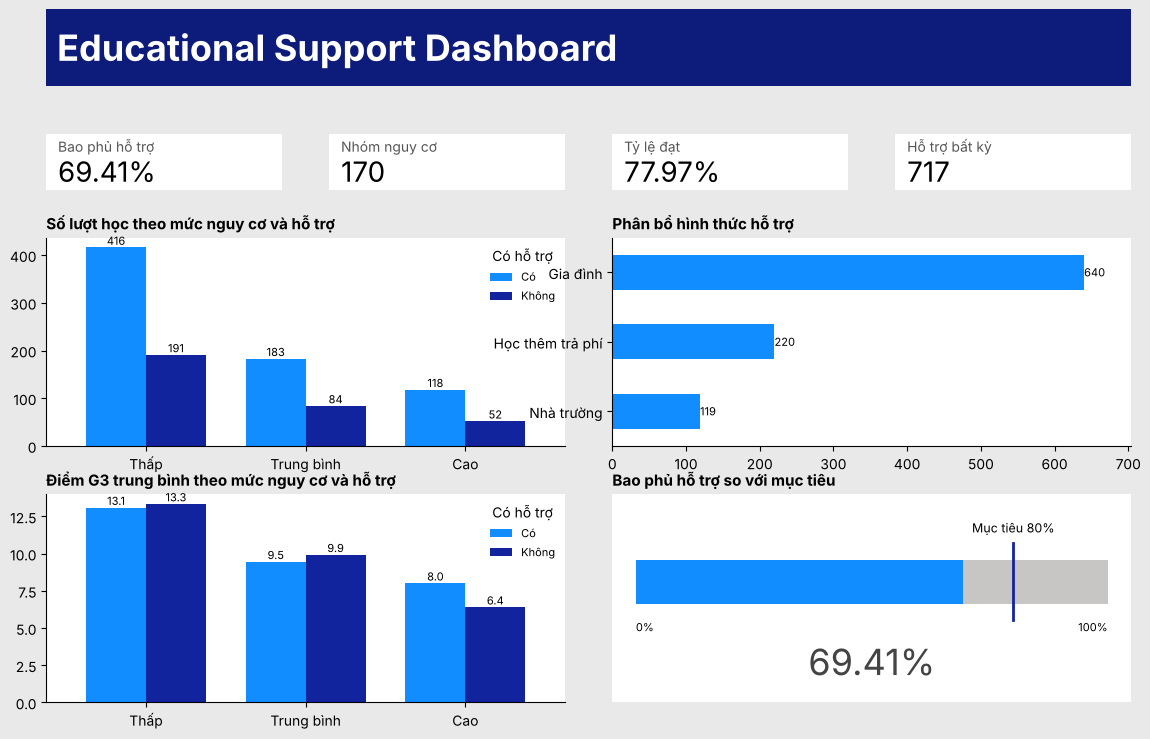

In [4]:
fig = ve_dashboard(df)
fig.savefig("dashboard.png", dpi=150, bbox_inches="tight")
plt.show()

## Bước 5. Thay slicer: lọc rồi truyền vào hàm

Power BI có slicer `Subject`. Ở đây chỉ cần lọc bảng trước, rồi gọi lại cùng hàm.
Đối chiếu: môn Toán phải ra **Nhóm nguy cơ = 83**, **Bao phủ hỗ trợ = 72,29%**.

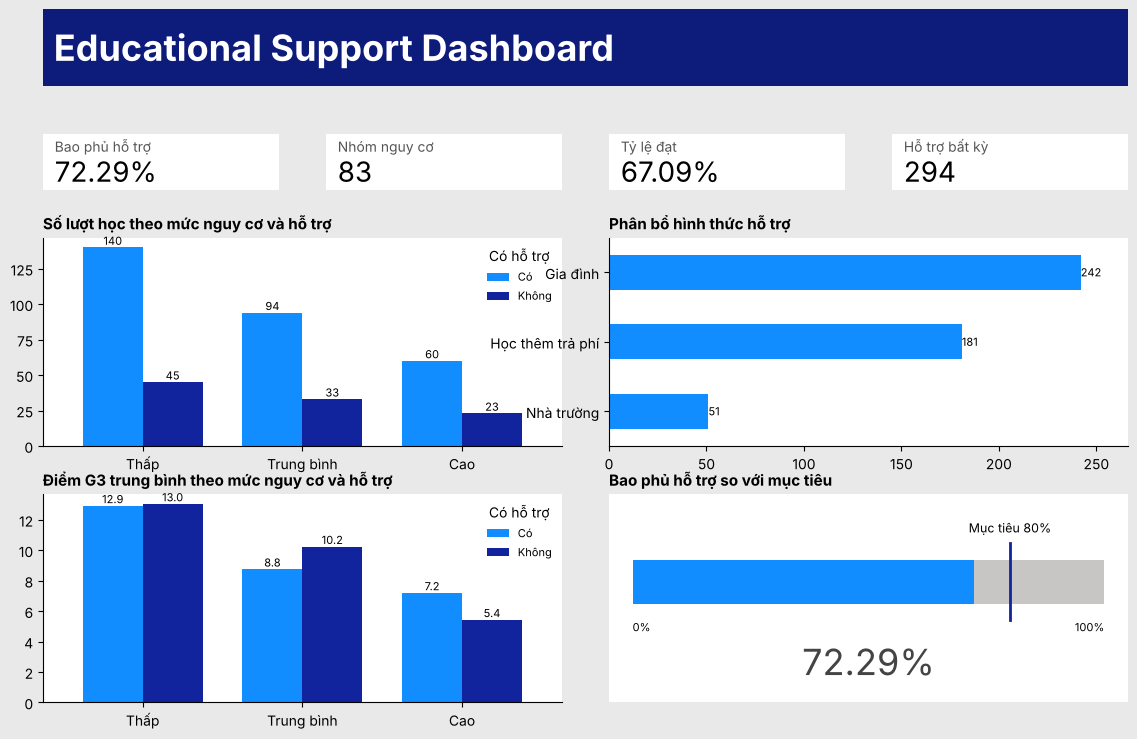

In [5]:
fig = ve_dashboard(df[df.Subject == "Math"])
plt.show()